# 跨品牌共同配送初步試作:東北角四區

**研究題目**:針對超商冷鏈運輸系統採用跨廠商合併配送策略對於減少碳排之潛力——以新北市瑞芳區全家超商為例

**試作範圍**:瑞芳、貢寮、雙溪、平溪四區;7-Eleven、全家、OK、萊爾富四大超商(不含全聯)

| 組別 | 配送方式 |
|---|---|
| A 組 | 各品牌各自規劃配送路線 |
| B 組 | 四品牌門市合併,共同規劃配送路線 |

- 四品牌都從同一入口(全家瑞芳物流中心座標)進出,只比較區內配送段,比法與日本函館實證一致。
- 排碳以瑞芳 7 輛冷藏配送車 CAN 實測油耗換算,只計行駛;停靠次數 A、B 組相同,停靠怠速不變。
- 網路查詢(OpenStreetMap、OSRM)的結果都快取在 `poc/` 資料夾,重新執行時不會重複連線;刪除快取檔才會重新查詢。

In [1]:
import itertools, json, math, os, time, urllib.parse, urllib.request

import matplotlib.pyplot as plt
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from pyvrp import Model
from pyvrp.stop import MaxRuntime
from shapely.geometry import LineString, Point
from shapely.ops import polygonize, unary_union

pio.renderers.default = "plotly_mimetype+notebook_connected"
plt.rcParams.update({"font.family": "Microsoft JhengHei", "axes.unicode_minus": False, "figure.dpi": 120,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.max_columns", 20)

ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "poc" else os.getcwd()
POC = os.path.join(ROOT, "poc")
P = lambda *a: os.path.join(POC, *a)
UA = {"User-Agent": "course-research/1.0"}

# ---- 參數 ----
FUEL_L_PER_100KM = 21.2   # 瑞芳 7 車 CAN 實測平均油耗
DIESEL_KG_PER_L = 2.60    # 環境部柴油係數 74,100 kg CO2/TJ × 35.15 MJ/L
SERVICE_MIN = 10          # 每店停靠時間假設(只影響時間指標)
Q_LIST = [10, 15, 20, 25] # 每趟最多停靠店數(容量假設)
Q_BASE = 20               # 瑞芳資料任務 05/12 每趟停靠中位數約 20–21
SOLVE_SEC = 2             # 每題求解秒數
DIESEL_PRICE = 29.9       # 台灣中油超級柴油牌價(元/公升,115/10/05),含稅零售價
DEPART = "07:00"          # 出發時間假設(只用於推算最晚到店時間)
BRANDS = ["7-Eleven", "全家", "OK", "萊爾富"]
BCOL = {"7-Eleven": "#2a78d6", "全家": "#1baf7a", "OK": "#eb6834", "萊爾富": "#4a3aa7"}
print("專案根目錄:", ROOT)

專案根目錄: C:\Users\a0903\Documents\slides\綠色工程專題研究\course_data\course_data


## 1. 門市資料

- **全家**:取自 `store_master.csv`(含座標)。
- **其他品牌**:取自 OpenStreetMap 的 `shop=convenience` 標記,再以四區行政區界判斷所在區。

政府資料開放平臺「全國5大超商資料集」(dataset 32086)四區營業中分公司數為 7-Eleven 17、全家 8、OK 4、萊爾富 2,但該資料集不含加盟店;OpenStreetMap 則可能仍有已歇業門市。

因此流程分兩步:
1. 由 OpenStreetMap 與全家門市主檔自動產生**候選清單**(`ne_stores_candidates.csv`);
2. 小組到各品牌官網核對後,整理成**核對清單**(`ne_stores_verified.csv`),記錄每家店的地址、座標來源、核對狀態與是否納入(`include`)。已歇業的店標為排除,不刪除,方便追溯。**模型只使用核對清單中 `include = 1` 的門市。**

In [2]:
def overpass(query, timeout=120):
    for ep in ["https://lz4.overpass-api.de/api/interpreter", "https://z.overpass-api.de/api/interpreter",
               "https://overpass-api.de/api/interpreter"]:
        try:
            req = urllib.request.Request(ep, data=urllib.parse.urlencode({"data": query}).encode(), headers=UA)
            return json.load(urllib.request.urlopen(req, timeout=timeout))
        except Exception as e:
            print("Overpass 失敗:", ep, str(e)[:60])
    raise RuntimeError("所有 Overpass 伺服器都失敗,請稍後再試")

# 四區行政界(快取)
if not os.path.exists(P("osm_ne_boundaries.json")):
    q = '[out:json][timeout:25];relation["boundary"="administrative"]["name"~"^(瑞芳區|貢寮區|雙溪區|平溪區)$"](24.85,121.6,25.2,122.1);out geom;'
    json.dump(overpass(q), open(P("osm_ne_boundaries.json"), "w", encoding="utf-8"), ensure_ascii=False)
bnd = json.load(open(P("osm_ne_boundaries.json"), encoding="utf-8"))
polys = {}
for rel in bnd["elements"]:
    lines = [LineString([(p["lon"], p["lat"]) for p in m["geometry"]]) for m in rel["members"]
             if m["type"] == "way" and m.get("role") in ("outer", "") and "geometry" in m]
    polys[rel["tags"]["name"]] = unary_union(list(polygonize(unary_union(lines))))

# OpenStreetMap 便利商店(快取)
if not os.path.exists(P("ne_stores_osm.csv")):
    q = '[out:json][timeout:25];nwr["shop"="convenience"](24.95,121.68,25.14,122.02);out center tags;'
    rows = []
    for e in overpass(q)["elements"]:
        t = e.get("tags", {})
        rows.append(dict(brand=t.get("brand", ""), name=t.get("name", ""), branch=t.get("branch", ""),
                         lat=e.get("lat", e.get("center", {}).get("lat")), lon=e.get("lon", e.get("center", {}).get("lon"))))
    osm_all = pd.DataFrame(rows)
    osm_all["區"] = [next((k for k, v in polys.items() if v.contains(Point(x, y))), None) for x, y in zip(osm_all.lon, osm_all.lat)]
    osm_all["品牌"] = osm_all.brand.map({"7-Eleven": "7-Eleven", "全家便利商店": "全家", "OK超商": "OK", "萊爾富": "萊爾富"})
    osm_all[osm_all["區"].notna()].to_csv(P("ne_stores_osm.csv"), index=False, encoding="utf-8-sig")
osm = pd.read_csv(P("ne_stores_osm.csv"), encoding="utf-8-sig")
osm = osm[osm["品牌"].isin(["7-Eleven", "OK", "萊爾富"])]

st = pd.read_csv(os.path.join(ROOT, "store_master", "store_master.csv"), encoding="utf-8-sig")
dc = st[st["name"] == "瑞芳ＤＣ"].iloc[0]
fm = st[st["address"].str.contains("瑞芳區|貢寮區|雙溪區|平溪區", na=False) & (st["name"] != "瑞芳ＤＣ")]

stores = pd.concat([
    pd.DataFrame({"brand": "全家", "name": fm["name"], "district": fm["address"].str.extract(r"(瑞芳|貢寮|雙溪|平溪)區")[0] + "區",
                  "lat": fm["lat"], "lon": fm["lng"], "source": "store_master"}),
    pd.DataFrame({"brand": osm["品牌"], "name": (osm["品牌"] + " " + osm["branch"].fillna("").astype(str)).str.strip(),
                  "district": osm["區"], "lat": osm["lat"], "lon": osm["lon"], "source": "OpenStreetMap"}),
], ignore_index=True)
candidates = stores
candidates.to_csv(P("ne_stores_candidates.csv"), index=False, encoding="utf-8-sig")
print("候選清單(OpenStreetMap + 全家門市主檔):", len(candidates), "家")

候選清單(OpenStreetMap + 全家門市主檔): 36 家


In [3]:
ver = pd.read_csv(P("ne_stores_verified.csv"), encoding="utf-8-sig")
display(pd.crosstab([ver["brand"], ver["verification"]], ver["include"].map({1: "納入", 0: "排除"}))
        .reindex(columns=["納入", "排除"], fill_value=0))
stores = ver[ver["include"] == 1].reset_index(drop=True)
print(f"模型使用 {len(stores)} 家門市;排除 {int((ver['include'] == 0).sum())} 家(原因見 note 欄)")
pd.crosstab(stores["brand"], stores["district"], margins=True, margins_name="合計").reindex(BRANDS + ["合計"])

include                          納入  排除
brand    verification                  
7-Eleven 官網確認(2026-10-09)         4   0
         已排除:歇業                   0   1
         待核對                     13   0
OK       官網確認(2026-10-09)         3   0
         官網確認(2026-10-09);座標待確認   1   0
         已排除:歇業                   0   3
全家       全家門市主檔                  10   0
萊爾富      待核對                      2   0

模型使用 33 家門市;排除 4 家(原因見 note 欄)


district,平溪區,瑞芳區,貢寮區,雙溪區,合計
brand,,,,,
7-Eleven,1,10,4,2,17
全家,2,6,2,0,10
OK,0,4,0,0,4
萊爾富,0,2,0,0,2
合計,3,22,6,2,33


## 2. 道路距離矩陣

以 OSRM 公開服務(OpenStreetMap 路網)計算入口與各門市之間的行車距離與時間。快取以座標判斷,門市清單一變動就會自動重新查詢。

In [4]:
pts = [(dc["lng"], dc["lat"])] + list(zip(stores["lon"], stores["lat"]))
coords_key = ";".join(f"{x:.6f},{y:.6f}" for x, y in pts)
if os.path.exists(P("osrm_matrix.json")) and json.load(open(P("osrm_matrix.json"))).get("key") == coords_key:
    M = json.load(open(P("osrm_matrix.json")))
else:
    coords = ";".join(f"{x:.6f},{y:.6f}" for x, y in pts)
    r = json.load(urllib.request.urlopen(urllib.request.Request(
        f"https://router.project-osrm.org/table/v1/driving/{coords}?annotations=distance,duration", headers=UA), timeout=120))
    assert r["code"] == "Ok"
    M = {"n": len(pts), "key": coords_key, "distances": r["distances"], "durations": r["durations"]}
    json.dump(M, open(P("osrm_matrix.json"), "w"))
D = [[int(round(v)) for v in row] for row in M["distances"]]   # 公尺
T = [[int(round(v)) for v in row] for row in M["durations"]]   # 秒
far = pd.Series([D[0][i + 1] / 1000 for i in stores.index], index=stores["name"]).sort_values(ascending=False)
print(f"點數:{len(pts)}(入口 1 + 門市 {len(stores)})")
print("離入口最遠的 5 家(單程 km):"); print(far.head().round(1).to_string())

點數:34(入口 1 + 門市 33)
離入口最遠的 5 家(單程 km):
name
7-Eleven 福隆站    34.5
全家鑫福隆店          34.5
7-Eleven 新福隆    34.4
7-Eleven 貢寮     29.3
7-Eleven 金澳底    29.1


## 3. 模型

每一組都解一個**有容量限制的車輛路線問題(CVRP)**:從入口出發、服務指定門市、回到入口,目標是總行駛距離最短。

- 沒有任何超商的貨量資料,所以每店需求設為 1 單位,車輛容量 = 每趟最多停靠店數 Q。
- 求解器:PyVRP。

In [5]:
def solve(idx, Q):
    # idx:門市索引;回傳總里程 km、各趟路線、行駛時數
    if not idx:
        return dict(km=0.0, routes=[], drive_h=0.0)
    m = Model()
    loc0 = m.add_location(x=pts[0][0], y=pts[0][1])
    m.add_depot(loc0)
    m.add_vehicle_type(num_available=len(idx), capacity=Q)
    locs = [loc0]
    for i in idx:
        L = m.add_location(x=pts[i + 1][0], y=pts[i + 1][1])
        m.add_client(L, delivery=1, service_duration=SERVICE_MIN * 60)
        locs.append(L)
    g = [0] + [i + 1 for i in idx]
    for a, la in zip(g, locs):
        for b, lb in zip(g, locs):
            m.add_edge(la, lb, distance=D[a][b], duration=T[a][b])
    sol = m.solve(stop=MaxRuntime(SOLVE_SEC), seed=1, display=False).best
    assert sol.is_feasible()
    routes = [[idx[a.idx] for a in r.schedule() if a.is_client()] for r in sol.routes()]
    drive_h = sum(T[a][b] for r in routes for a, b in zip([0] + [i + 1 for i in r], [i + 1 for i in r] + [0])) / 3600
    return dict(km=sol.distance() / 1000, routes=routes, drive_h=drive_h)

co2_kg = lambda km: km * FUEL_L_PER_100KM / 100 * DIESEL_KG_PER_L
brand_idx = {b: stores.index[stores["brand"] == b].tolist() for b in BRANDS}
all_idx = stores.index.tolist()

## 4. A 組 vs B 組(含容量敏感度)

In [6]:
rows, detail = [], {}
for Q in Q_LIST:
    A = {b: solve(brand_idx[b], Q) for b in BRANDS}
    B = solve(all_idx, Q)
    a_km = sum(v["km"] for v in A.values())
    rows.append({"每趟最多店數 Q": Q, "A 組 km": a_km, "B 組 km": B["km"], "減少 km": a_km - B["km"],
                 "減少比例": (a_km - B["km"]) / a_km, "A 組趟數": sum(len(v["routes"]) for v in A.values()),
                 "B 組趟數": len(B["routes"]), "A 組行駛時數": sum(v["drive_h"] for v in A.values()), "B 組行駛時數": B["drive_h"],
                 "A 組 CO₂ kg": co2_kg(a_km), "B 組 CO₂ kg": co2_kg(B["km"])})
    detail[Q] = dict(A=A, B=B)
summary = pd.DataFrame(rows)
summary.style.format({"A 組 km": "{:.1f}", "B 組 km": "{:.1f}", "減少 km": "{:.1f}", "減少比例": "{:.0%}",
                      "A 組行駛時數": "{:.1f}", "B 組行駛時數": "{:.1f}", "A 組 CO₂ kg": "{:.0f}", "B 組 CO₂ kg": "{:.0f}"}).hide(axis="index")

每趟最多店數 Q,A 組 km,B 組 km,減少 km,減少比例,A 組趟數,B 組趟數,A 組行駛時數,B 組行駛時數,A 組 CO₂ kg,B 組 CO₂ kg
10,238.6,150.7,87.9,37%,6,4,6.6,4.3,132,83
15,234.6,126.6,108.0,46%,6,3,6.5,3.6,129,70
20,224.4,109.0,115.5,51%,5,2,6.1,3.1,124,60
25,224.4,106.7,117.7,52%,5,2,6.1,3.0,124,59


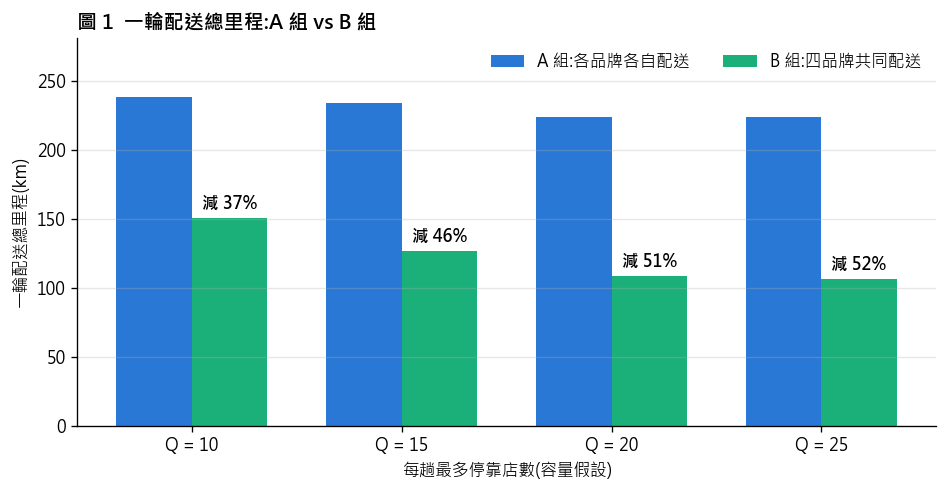

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.2))
x = range(len(summary)); w = 0.36
b1 = ax.bar([i - w / 2 for i in x], summary["A 組 km"], w, label="A 組:各品牌各自配送", color="#2a78d6")
b2 = ax.bar([i + w / 2 for i in x], summary["B 組 km"], w, label="B 組:四品牌共同配送", color="#1baf7a")
for bar, p in zip(b2, summary["減少比例"]):
    ax.annotate(f"減 {p:.0%}", (bar.get_x() + bar.get_width() / 2, bar.get_height()), ha="center", va="bottom",
                xytext=(0, 3), textcoords="offset points", fontsize=10, fontweight="bold")
ax.set_xticks(list(x), [f"Q = {q}" for q in summary["每趟最多店數 Q"]])
ax.set_xlabel("每趟最多停靠店數(容量假設)"); ax.set_ylabel("一輪配送總里程(km)")
ax.set_title("圖 1  一輪配送總里程:A 組 vs B 組", loc="left", fontweight="bold")
ax.set_ylim(0, summary["A 組 km"].max() * 1.18); ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="upper right", ncols=2)
plt.tight_layout(); plt.show()

### 4.1 評估指標(對應提案第二節的指標表)

資料中沒有任何品牌的**貨量**(箱數、籠車數、件數)與**門市收貨時間窗**,所以原本的五項指標中:

| 原指標 | 能否計算 | 本試作的做法 |
|---|---|---|
| 配送總里程 | ✅ 可以 | 直接計算 |
| 車輛需求量 | ✅ 可以 | 每趟一臺車,以趟數表示 |
| 每件配送成本 | ⚠️ 沒有件數 | 改為**每店配送燃料成本**:里程 × 實測油耗 × 柴油牌價 ÷ 門市數(不含人力、車輛折舊) |
| 裝載率 | ⚠️ 沒有貨量 | 改為**以停靠店數估計的車輛使用率**:門市數 ÷(趟數 × 每趟最多店數) |
| 準時率 | ❌ 沒有時間窗 | 無法計算;改列**最長單趟工時**與**最晚到店時間**,作為時間窗風險的參考 |

In [8]:
def route_profile(route):
    # 回傳單趟:行駛時間(秒)、到各店的累計時間(秒,含停靠)
    seq = [0] + [i + 1 for i in route] + [0]
    t, arrive = 0, []
    for k, (a, b) in enumerate(zip(seq[:-1], seq[1:])):
        t += T[a][b]
        if k < len(route):
            arrive.append(t)
            t += SERVICE_MIN * 60
    return t, arrive

def indicators(routes, km):
    n_store = sum(len(r) for r in routes)
    prof = [route_profile(r) for r in routes]
    longest = max(p[0] for p in prof) / 3600
    last_arrive = max(max(p[1]) for p in prof) / 3600
    h0, m0 = map(int, DEPART.split(":"))
    clock = h0 + m0 / 60 + last_arrive
    fuel_l = km * FUEL_L_PER_100KM / 100
    return {
        "配送總里程(km)": round(km, 1),
        "車輛需求量(趟/車)": len(routes),
        "車輛使用率(停靠店數估計)": f"{n_store / (len(routes) * Q_BASE):.0%}",
        "每店配送里程(km/店)": round(km / n_store, 2),
        "每店配送燃料成本(元/店)": round(fuel_l * DIESEL_PRICE / n_store, 1),
        "每店行駛 CO₂(kg/店)": round(co2_kg(km) / n_store, 2),
        "最長單趟工時(小時,含停靠)": round(longest, 1),
        f"最晚到店時間({DEPART} 出發)": f"{int(clock):02d}:{int(round(clock % 1 * 60)):02d}",
        "準時率": "無法計算(無時間窗)",
    }

base = detail[Q_BASE]
A_routes = [r for b in BRANDS for r in base["A"][b]["routes"]]
A_km = sum(base["A"][b]["km"] for b in BRANDS)
ind = pd.DataFrame({"A 組:各自配送": indicators(A_routes, A_km),
                    "B 組:共同配送": indicators(base["B"]["routes"], base["B"]["km"])})
ind.index.name = f"指標(每趟最多 {Q_BASE} 店)"
ind

,A 組:各自配送,B 組:共同配送
指標(每趟最多 20 店),,
配送總里程(km),224.4,109.0
車輛需求量(趟/車),5,2
車輛使用率(停靠店數估計),33%,82%
每店配送里程(km/店),6.8,3.3
每店配送燃料成本(元/店),43.1,20.9
每店行駛 CO₂(kg/店),3.75,1.82
"最長單趟工時(小時,含停靠)",5.3,5.9
最晚到店時間(07:00 出發),11:55,12:30
準時率,無法計算(無時間窗),無法計算(無時間窗)


## 5. 路線地圖(Q = 20)

路線為 OSRM 道路路線。點地圖左上角按鈕切換 A、B 組;下方另附靜態對照圖。

In [9]:
entry = (dc["lng"], dc["lat"])
cache_f = P("osrm_routes.json")
cache = json.load(open(cache_f, encoding="utf-8")) if os.path.exists(cache_f) else {}

def geometry(route):
    seq = [entry] + [(stores.at[i, "lon"], stores.at[i, "lat"]) for i in route] + [entry]
    key = ";".join(f"{x:.6f},{y:.6f}" for x, y in seq)
    if key not in cache:
        r = json.load(urllib.request.urlopen(urllib.request.Request(
            f"https://router.project-osrm.org/route/v1/driving/{key}?overview=full&geometries=geojson", headers=UA), timeout=60))
        cache[key] = r["routes"][0]["geometry"]["coordinates"]
    return cache[key]

base = detail[Q_BASE]
geomA = {b: [geometry(r) for r in base["A"][b]["routes"]] for b in BRANDS}
geomB = [geometry(r) for r in base["B"]["routes"]]
json.dump(cache, open(cache_f, "w", encoding="utf-8"))

JOINT = ["#0b0b0b", "#e34948", "#eda100", "#e87ba4"]
fig = go.Figure()
nA = 0
for b in BRANDS:
    for k, g in enumerate(geomA[b]):
        fig.add_trace(go.Scattermapbox(lon=[p[0] for p in g], lat=[p[1] for p in g], mode="lines", line=dict(width=3, color=BCOL[b]),
                                       name=f"A 組:{b}", legendgroup=b, showlegend=(k == 0), hoverinfo="name")); nA += 1
for k, g in enumerate(geomB):
    fig.add_trace(go.Scattermapbox(lon=[p[0] for p in g], lat=[p[1] for p in g], mode="lines",
                                   line=dict(width=3, color=JOINT[k % 4]), name=f"B 組:共配車 {k + 1}", hoverinfo="name", visible=False))
for b in BRANDS:
    s = stores[stores["brand"] == b]
    fig.add_trace(go.Scattermapbox(lon=s["lon"], lat=s["lat"], mode="markers", marker=dict(size=10, color=BCOL[b]),
                                   name=f"門市:{b}", text=s["name"] + "(" + s["district"] + ")", hovertemplate="%{text}<extra></extra>"))
fig.add_trace(go.Scattermapbox(lon=[entry[0]], lat=[entry[1]], mode="markers+text", marker=dict(size=15, color="#0b0b0b"),
                               text=["入口(瑞芳物流中心)"], textposition="top right", name="共同入口"))
nB, nM = len(geomB), len(BRANDS) + 1
fig.update_layout(
    mapbox=dict(style="white-bg", center=dict(lat=25.07, lon=121.85), zoom=10.2,
                layers=[dict(below="traces", sourcetype="raster", sourceattribution="Tiles © Esri",
                             source=["https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}"])]),
    updatemenus=[dict(type="buttons", direction="right", x=0.01, y=0.99, xanchor="left", yanchor="top", buttons=[
        dict(label="A 組:各自配送", method="update", args=[{"visible": [True] * nA + [False] * nB + [True] * nM}]),
        dict(label="B 組:共同配送", method="update", args=[{"visible": [False] * nA + [True] * nB + [True] * nM}])])],
    height=600, margin=dict(t=10, b=10, l=10, r=10), font=dict(family="Microsoft JhengHei"),
    legend=dict(bgcolor="rgba(255,255,255,0.85)", x=0.99, xanchor="right", y=0.01))
fig.show()

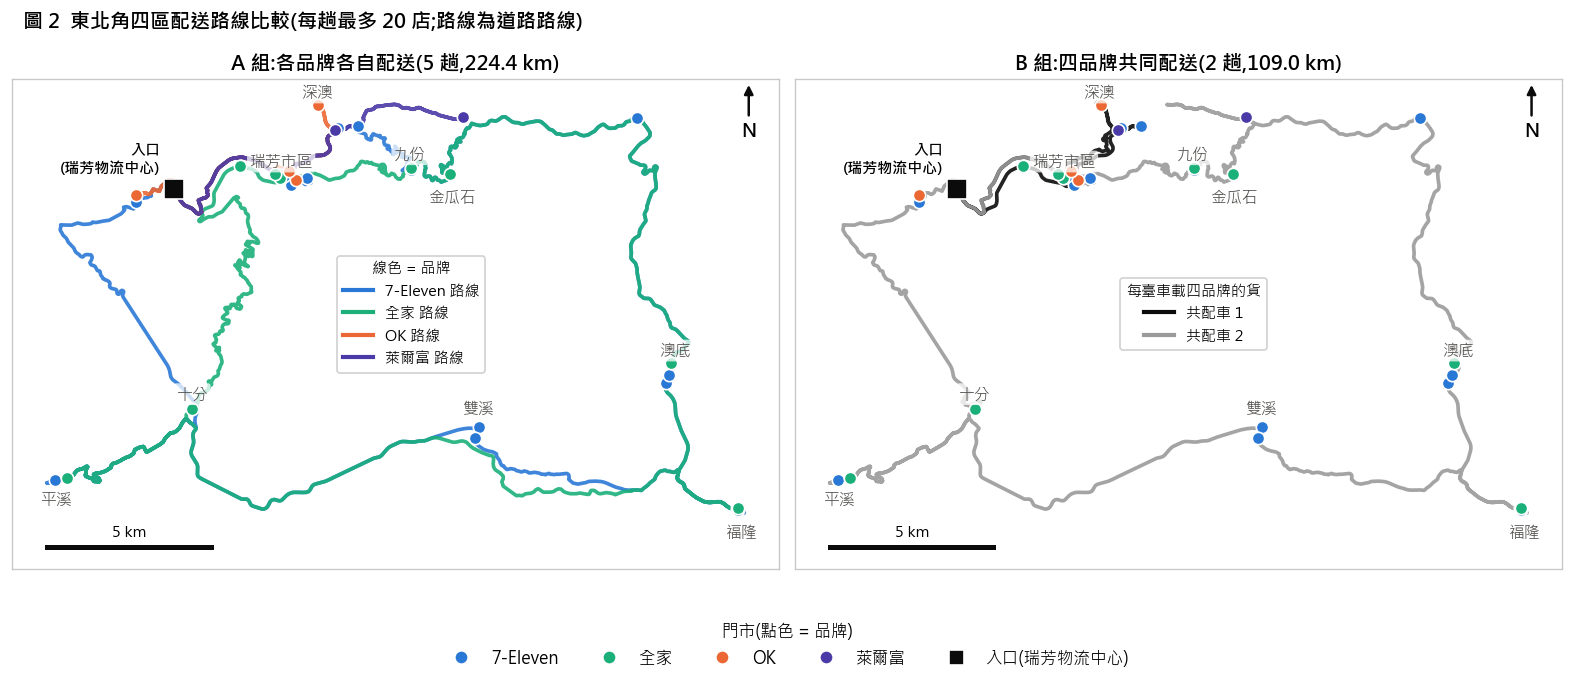

In [10]:
from matplotlib.lines import Line2D

PLACES = {"瑞芳市區": (121.806, 25.112), "九份": (121.845, 25.114), "金瓜石": (121.858, 25.102), "深澳": (121.817, 25.131),
          "十分": (121.779, 25.048), "平溪": (121.738, 25.019), "雙溪": (121.866, 25.044), "澳底": (121.926, 25.060), "福隆": (121.946, 25.010)}
JOINT_STYLE = [dict(color="#0b0b0b", ls="-"), dict(color="#9a9a9a", ls="-"), dict(color="#0b0b0b", ls=":"), dict(color="#9a9a9a", ls=":")]
kmA = sum(r["km"] for r in base["A"].values()); nA_routes = sum(len(r["routes"]) for r in base["A"].values())
kmB = base["B"]["km"]; nB_routes = len(base["B"]["routes"])
lon0, lat0 = 121.735, 25.006   # 比例尺起點(左下角)
deg_per_km = 1 / (111.32 * math.cos(math.radians(25.07)))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.6), sharex=True, sharey=True, layout="constrained")
for b in BRANDS:
    for g in geomA[b]:
        axes[0].plot([p[0] for p in g], [p[1] for p in g], color=BCOL[b], lw=2.2, alpha=0.9, solid_capstyle="round")
for k, g in enumerate(geomB):
    axes[1].plot([p[0] for p in g], [p[1] for p in g], lw=2.2, alpha=0.9, **JOINT_STYLE[k % 4])

for ax, title in zip(axes, [f"A 組:各品牌各自配送({nA_routes} 趟,{kmA:.1f} km)",
                            f"B 組:四品牌共同配送({nB_routes} 趟,{kmB:.1f} km)"]):
    for b in BRANDS:
        s = stores[stores["brand"] == b]
        ax.scatter(s["lon"], s["lat"], s=55, color=BCOL[b], edgecolor="white", linewidth=1.0, zorder=4)
    ax.scatter([entry[0]], [entry[1]], s=130, marker="s", color="#0b0b0b", edgecolor="white", zorder=5)
    ax.annotate("入口\n(瑞芳物流中心)", entry, xytext=(-8, 10), textcoords="offset points", ha="right", fontsize=9, fontweight="bold")
    for name, (x, y) in PLACES.items():
        ax.text(x, y, name, fontsize=9.5, color="#52514e", ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.75), zorder=6)
    ax.plot([lon0, lon0 + 5 * deg_per_km], [lat0, lat0], color="#0b0b0b", lw=3)
    ax.text(lon0 + 2.5 * deg_per_km, lat0 + 0.003, "5 km", ha="center", fontsize=9)
    ax.annotate("N", xy=(121.948, 25.134), xytext=(121.948, 25.119), ha="center", fontsize=11, fontweight="bold",
                arrowprops=dict(arrowstyle="-|>", color="#0b0b0b", lw=1.5))
    ax.set_title(title, fontweight="bold", fontsize=12)
    ax.set_aspect(1 / math.cos(math.radians(25.07)))
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for sp in ax.spines.values():
        sp.set_visible(True); sp.set_color("#c9c8c4")

route_h = [Line2D([0], [0], color=BCOL[b], lw=2.5, label=f"{b} 路線") for b in BRANDS]
axes[0].legend(handles=route_h, title="線色 = 品牌", loc="center", bbox_to_anchor=(0.52, 0.52), fontsize=9, title_fontsize=9, frameon=True, framealpha=0.9)
joint_h = [Line2D([0], [0], lw=2.5, label=f"共配車 {k + 1}", **JOINT_STYLE[k % 4]) for k in range(nB_routes)]
axes[1].legend(handles=joint_h, title="每臺車載四品牌的貨", loc="center", bbox_to_anchor=(0.52, 0.52), fontsize=9, title_fontsize=9, frameon=True, framealpha=0.9)
store_h = [Line2D([0], [0], marker="o", ls="", markersize=8, markerfacecolor=BCOL[b], markeredgecolor="white", label=b) for b in BRANDS]
store_h.append(Line2D([0], [0], marker="s", ls="", markersize=9, markerfacecolor="#0b0b0b", markeredgecolor="white", label="入口(瑞芳物流中心)"))
fig.legend(handles=store_h, title="門市(點色 = 品牌)", loc="outside lower center", ncols=5, frameon=False, fontsize=10, title_fontsize=10)
fig.suptitle(f"圖 2  東北角四區配送路線比較(每趟最多 {Q_BASE} 店;路線為道路路線)", x=0.01, ha="left", fontweight="bold")
plt.show()

## 6. 品牌組合與 Shapley value

把 4 個品牌的 15 種組合各解一次,計算:
- 兩兩共配各能減少多少里程;
- 四品牌共配省下的里程,依 **Shapley value**(各品牌加入合作時的平均邊際貢獻)分給各品牌,可作為成本或利益分攤的討論基礎。

In [11]:
coal = {}
for k in range(1, len(BRANDS) + 1):
    for S in itertools.combinations(BRANDS, k):
        coal[S] = solve(sum((brand_idx[b] for b in S), []), Q_BASE)["km"]
stand = {b: coal[(b,)] for b in BRANDS}
v = lambda S: sum(stand[b] for b in S) - coal[tuple(b for b in BRANDS if b in S)] if S else 0.0

n = len(BRANDS); shap = {}
for b in BRANDS:
    others = [x for x in BRANDS if x != b]
    shap[b] = sum(math.factorial(k) * math.factorial(n - k - 1) / math.factorial(n) * (v(S + (b,)) - v(S))
                  for k in range(len(others) + 1) for S in itertools.combinations(others, k))

pairs = pd.DataFrame([{"品牌組合": " + ".join(S), "各自配送 km": sum(stand[b] for b in S), "共同配送 km": coal[S]}
                      for S in coal if len(S) == 2])
pairs["減少比例"] = 1 - pairs["共同配送 km"] / pairs["各自配送 km"]
display(pairs.sort_values("減少比例", ascending=False).style.format(
    {"各自配送 km": "{:.1f}", "共同配送 km": "{:.1f}", "減少比例": "{:.0%}"}).hide(axis="index"))

shap_df = pd.DataFrame({"品牌": BRANDS, "各自配送 km": [stand[b] for b in BRANDS], "分得的節省 km": [shap[b] for b in BRANDS]})
shap_df["佔總節省"] = shap_df["分得的節省 km"] / shap_df["分得的節省 km"].sum()
shap_df["相對自己的節省"] = shap_df["分得的節省 km"] / shap_df["各自配送 km"]
display(shap_df.style.format({"各自配送 km": "{:.1f}", "分得的節省 km": "{:.1f}", "佔總節省": "{:.0%}",
                              "相對自己的節省": "{:.0%}"}).hide(axis="index"))
print(f"四品牌共配總節省 {v(tuple(BRANDS)):.1f} km;Shapley 分配合計 {sum(shap.values()):.1f} km")

品牌組合,各自配送 km,共同配送 km,減少比例
7-Eleven + 全家,178.0,102.9,42%
OK + 萊爾富,46.5,30.5,34%
7-Eleven + 萊爾富,114.1,90.9,20%
全家 + 萊爾富,112.7,92.0,18%
全家 + OK,110.3,93.1,16%
7-Eleven + OK,111.7,95.7,14%


品牌,各自配送 km,分得的節省 km,佔總節省,相對自己的節省
7-Eleven,89.7,42.4,37%,47%
全家,88.3,45.0,39%,51%
OK,22.0,12.4,11%,56%
萊爾富,24.4,15.6,14%,64%


四品牌共配總節省 115.5 km;Shapley 分配合計 115.5 km


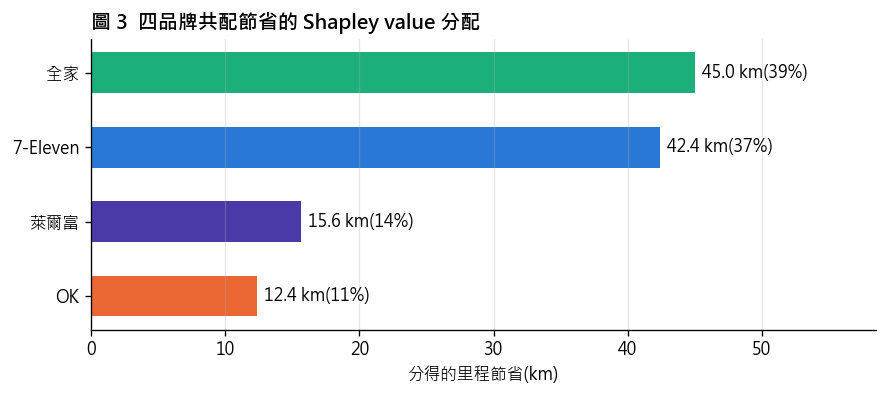

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
d = shap_df.sort_values("分得的節省 km")
bars = ax.barh(d["品牌"], d["分得的節省 km"], color=[BCOL[b] for b in d["品牌"]], height=0.55)
for bar, kmv, pct in zip(bars, d["分得的節省 km"], d["佔總節省"]):
    ax.annotate(f"{kmv:.1f} km({pct:.0%})", (bar.get_width(), bar.get_y() + bar.get_height() / 2),
                xytext=(4, 0), textcoords="offset points", va="center", fontsize=10)
ax.set_xlabel("分得的里程節省(km)"); ax.set_xlim(0, d["分得的節省 km"].max() * 1.3); ax.grid(axis="y", visible=False)
ax.set_title("圖 3  四品牌共配節省的 Shapley value 分配", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

## 7. 解讀與限制

**本試作的減幅應視為共配潛力的上限。** 日本函館偏遠地區的跨品牌門市共配實證(2022 年,7-Eleven 2 店 + Lawson 5 店,一週)為行駛距離 −22%(280.8 → 218.9 km)、時間 −20%、CO₂ −36.2 kg(日本全家 2022-10-17 新聞稿)。本試作減幅較高,主因如下表第一列。

| 項目 | 本試作的假設 | 對結果的影響 |
|---|---|---|
| **A 組配送方式** | 各品牌每輪都派車專程服務東北角門市 | **高估節省**:實際上各品牌可能把東北角門市與基隆、汐止門市排在同一趟;全家貢寮 2 店在瑞芳資料中由其他物流中心配送 |
| 出發點 | 四品牌都從瑞芳物流中心座標進出 | 與函館實證的比法一致 |
| 貨量 | 每店 1 單位,容量為每趟最多 Q 店 | 沒有任何品牌的貨量資料;真實裝載可能使 B 組需要更多趟 |
| 時間窗 | 未納入門市收貨時間 | 日本東京實證因收貨時間無法調整而未改善車輛生產力 |
| 溫層 | 視為同一溫層、可同車 | 不同溫層不能混載 |
| 門市清單 | 以 `ne_stores_verified.csv` 為準;7-Eleven 貢寮 4 家、OK 瑞芳 4 家已官網確認,並排除 4 家歇業店 | 7-Eleven 瑞芳、雙溪、平溪與萊爾富仍待核對;OK 瑞芳逢甲店座標為暫用值 |
| 排碳 | 21.2 L/100km × 2.60 kg CO₂/L | 只算行駛;停靠次數不變,停靠怠速不變 |
| 求解 | PyVRP,每題 2 秒 | 小規模問題,解的品質足夠,但不保證最佳 |

**下一步**:完成其餘門市的官網核對、以全家實際路線重建較真實的 A 組、加入時間窗與溫層、向教授或業者詢問各店貨量(籠車數或箱數)。